# ST-GCN với YOLO v26 và MotionBERT
Chạy `motionbert_3d_extraction.ipynb` hoàn tất các split `train/val/test` trước.
Notebook này đọc pose 3D H36M và confidence đã lưu, tạo 7 kênh `(x, y, z, confidence, dx, dy, dz)` rồi huấn luyện ST-GCN. Confidence kế thừa từ YOLO 2D.
Kết quả lưu riêng tại `processed/stgcn_v2_yolo26_motionbert`; cần huấn luyện mới với đầu vào 3D.

In [1]:
from pathlib import Path
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla V100-SXM2-16GB


In [2]:
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "pyproject.toml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án.")

JOINTS_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "joints_3d_motionbert"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "processed"
    / "stgcn_v2_yolo26_motionbert"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# Dữ liệu
TARGET_FRAMES = 64
CONFIDENCE_THRESHOLD = 0.20

# DataLoader
BATCH_SIZE = 64
NUM_WORKERS = 4

# Training
NUM_EPOCHS = 100
WARMUP_EPOCHS = 5

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
LABEL_SMOOTHING = 0.05

# Augmentation
HORIZONTAL_FLIP_PROBABILITY = 0.5
JOINT_NOISE_SIGMA = 0.01
FRAME_DROP_PROBABILITY = 0.05


assert JOINTS_ROOT.exists(), (
    f"Không tìm thấy: {JOINTS_ROOT}"
)

print("Joints root:", JOINTS_ROOT)
print("Output root:", OUTPUT_ROOT)
SCORES_ROOT = PROJECT_ROOT / "processed" / "scores_h36m_motionbert"
if not SCORES_ROOT.is_dir():
    raise FileNotFoundError(f"Chạy motionbert_3d_extraction.ipynb trước: {SCORES_ROOT}")
INPUT_FEATURES = ["normalized_x", "normalized_y", "normalized_z",
                  "confidence", "motion_x", "motion_y", "motion_z"]
INPUT_CHANNELS = len(INPUT_FEATURES)


Joints root: /home/dutai/khacbinh/badminton-stroke/processed/joints_3d_motionbert
Output root: /home/dutai/khacbinh/badminton-stroke/processed/stgcn_v2_yolo26_motionbert


In [3]:
def find_score_path(joint_path):
    relative = joint_path.relative_to(JOINTS_ROOT)
    score_path = SCORES_ROOT / relative.parent / relative.name.replace(
        "_joints3d.npy", "_scores_h36m.npy"
    )
    if not score_path.is_file():
        raise FileNotFoundError(f"Thiếu confidence H36M: {score_path}")
    return score_path


def build_index(split):
    split_root = JOINTS_ROOT / split

    assert split_root.exists(), (
        f"Không tìm thấy split: {split_root}"
    )

    records = []

    joint_files = sorted(
        split_root.rglob("*_joints3d.npy")
    )

    for joint_path in joint_files:
        relative_path = (
            joint_path.relative_to(split_root)
        )

        if len(relative_path.parts) < 2:
            raise RuntimeError(
                f"{joint_path} không nằm trong "
                "thư mục class."
            )

        label_name = relative_path.parts[0]
        score_path = find_score_path(joint_path)

        records.append(
            {
                "split": split,
                "label_name": label_name,
                "joint_path": str(joint_path),
                "score_path": (
                    str(score_path)
                    if score_path is not None
                    else ""
                ),
            }
        )

    frame = pd.DataFrame(records)

    assert len(frame) > 0, (
        f"Không tìm thấy *_joints3d.npy "
        f"trong {split_root}"
    )

    return frame


train_df = build_index("train")
val_df = build_index("val")
test_df = build_index("test")

class_names = sorted(
    train_df["label_name"]
    .unique()
    .tolist()
)

class_to_id = {
    class_name: class_id
    for class_id, class_name
    in enumerate(class_names)
}

for split_name, frame in {
    "val": val_df,
    "test": test_df,
}.items():
    unknown_classes = (
        set(frame["label_name"])
        - set(class_names)
    )

    assert not unknown_classes, (
        f"{split_name} có lớp không xuất hiện "
        f"trong train: {unknown_classes}"
    )

print("Số lớp:", len(class_names))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Các lớp:")

for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)

display(train_df.head())

Số lớp: 18
Train: 5462
Validation: 1176
Test: 1180
Các lớp:
0 00_Short Serve
1 01_Cross Court Flight
2 02_Lift
3 03_Tap Smash
4 04_Block
5 05_Drop Shot
6 06_Push Shot
7 07_Transitional Slice
8 08_Cut
9 09_Rush Shot
10 10_Defensive Clear
11 11_Defensive Drive
12 12_Clear
13 13_Long Serve
14 14_Smash
15 15_Flat Shot
16 16_Rear Court Flat Drive
17 17_Short Flat Shot


,split,label_name,joint_path,score_path
0,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...
1,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...
2,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...
3,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...
4,train,00_Short Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...


In [4]:
def load_scores(score_path, joints):
    scores = np.load(score_path).astype(np.float32)
    if scores.shape != joints.shape[:-1]:
        raise ValueError(f"Confidence shape {scores.shape} không khớp pose {joints.shape}: {score_path}")
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError(f"Confidence không hợp lệ: {score_path}")
    return scores


all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
)

audit_records = []

for row in tqdm(
    all_df.itertuples(index=False),
    total=len(all_df),
    desc="Audit dữ liệu",
):
    try:
        joints = np.load(
            row.joint_path,
            mmap_mode="r",
        )

        valid_shape = (
            joints.ndim == 4
            and joints.shape[1:] == (2, 17, 3)
        )

        scores = load_scores(row.score_path, joints)
        valid_shape = (
            valid_shape and len(joints) > 0
            and np.isfinite(joints).all()
            and np.isfinite(scores).all()
            and ((scores >= 0) & (scores <= 1)).all()
        )

        audit_records.append(
            {
                "split": row.split,
                "label_name": row.label_name,
                "num_frames": (
                    joints.shape[0]
                    if joints.ndim > 0
                    else 0
                ),
                "shape": tuple(joints.shape),
                "valid": valid_shape,
                "joint_path": row.joint_path,
                "error": "",
            }
        )

    except Exception as error:
        audit_records.append(
            {
                "split": row.split,
                "label_name": row.label_name,
                "num_frames": 0,
                "shape": None,
                "valid": False,
                "joint_path": row.joint_path,
                "error": (
                    f"{type(error).__name__}: "
                    f"{error}"
                ),
            }
        )

audit_df = pd.DataFrame(audit_records)

print(
    "File hợp lệ:",
    int(audit_df["valid"].sum()),
    "/",
    len(audit_df),
)

display(
    audit_df.loc[
        audit_df["valid"],
        "num_frames",
    ].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

invalid_df = audit_df[
    ~audit_df["valid"]
]

if len(invalid_df):
    display(invalid_df.head(20))
if len(invalid_df):
    raise ValueError("Dữ liệu 3D không hợp lệ; xem audit_df và chạy lại bước trích xuất.")


Audit dữ liệu: 100%|██████████| 7818/7818 [00:02<00:00, 2648.32it/s]

File hợp lệ: 7818 / 7818


count    7818.000000
mean       33.067920
std        12.479478
min         1.000000
50%        31.000000
75%        41.000000
90%        51.000000
95%        56.000000
99%        65.000000
max       104.000000
Name: num_frames, dtype: float64

split,test,train,val
label_name,,,
00_Short Serve,132,619,129
01_Cross Court Flight,35,111,20
02_Lift,127,529,102
03_Tap Smash,21,73,15
04_Block,59,214,42
05_Drop Shot,122,560,130
06_Push Shot,51,300,50
07_Transitional Slice,18,79,26
08_Cut,101,406,78


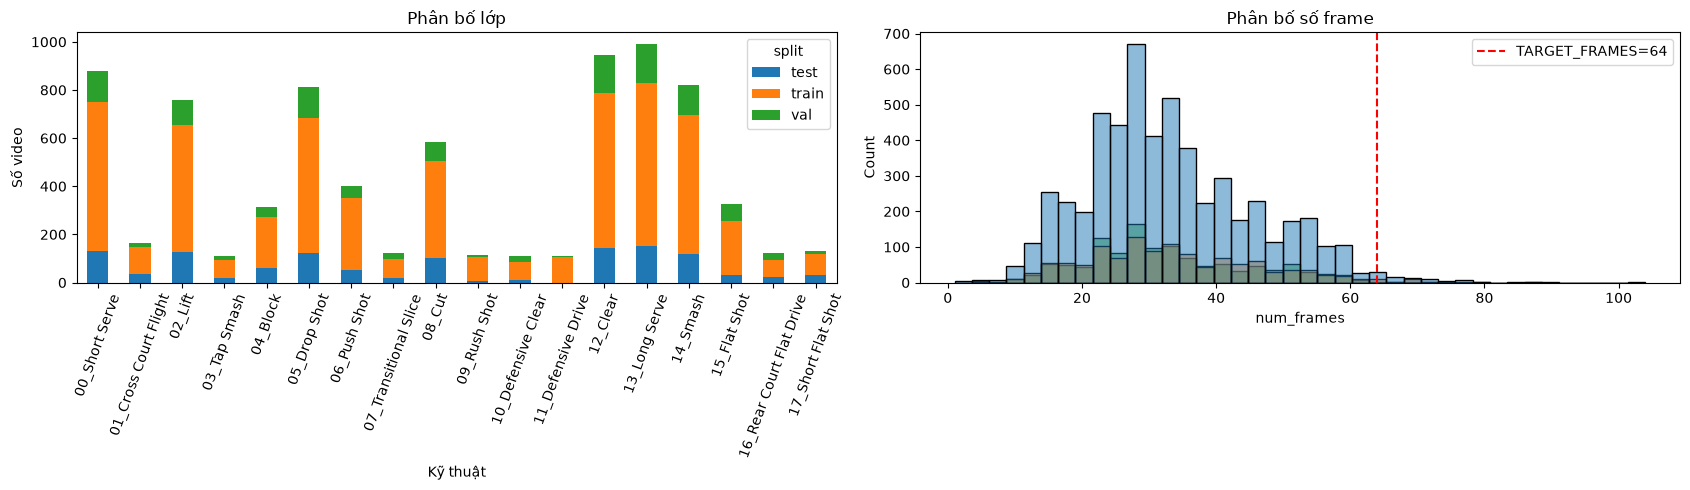

In [5]:
class_distribution = (
    all_df
    .groupby(["label_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(class_names)
)

display(class_distribution)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 5),
)

class_distribution.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
)

axes[0].set_title("Phân bố lớp")
axes[0].set_xlabel("Kỹ thuật")
axes[0].set_ylabel("Số video")
axes[0].tick_params(
    axis="x",
    rotation=70,
)

sns.histplot(
    data=audit_df[audit_df["valid"]],
    x="num_frames",
    hue="split",
    bins=40,
    ax=axes[1],
)

axes[1].axvline(
    TARGET_FRAMES,
    color="red",
    linestyle="--",
    label=f"TARGET_FRAMES={TARGET_FRAMES}",
)

axes[1].set_title("Phân bố số frame")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
# Human3.6M: pelvis=0, neck/thorax=8.
H36M_LEFT_RIGHT_PAIRS = [(1, 4), (2, 5), (3, 6),
                         (11, 14), (12, 15), (13, 16)]


def normalize_skeleton(joints, scores, confidence_threshold):
    """Pose 3D tương đối pelvis; chia theo median chiều dài thân mỗi người."""
    joints = joints.astype(np.float32, copy=True)
    scores = scores.astype(np.float32, copy=True)
    valid = (scores > 0) & (scores >= confidence_threshold)
    normalized = np.zeros_like(joints)
    for person_index in range(joints.shape[1]):
        xyz = joints[:, person_index]
        visible = valid[:, person_index]
        centered = xyz - xyz[:, 0:1, :]
        torso_valid = visible[:, 0] & visible[:, 8]
        lengths = np.linalg.norm(centered[:, 8], axis=-1)
        lengths = lengths[torso_valid & (lengths > 1e-6)]
        if len(lengths):
            scale = float(np.median(lengths))
        else:
            points = centered[visible]
            scale = float(np.max(np.ptp(points, axis=0))) if len(points) else 1.0
        centered /= max(scale, 1e-6)
        centered[~visible] = 0.0
        normalized[:, person_index] = centered
    scores[~valid] = 0.0
    return normalized, scores


In [7]:
def crop_or_pad(
    joints,
    scores,
    target_frames,
    training,
):
    """
    Giữ nguyên frame rate.

    Video dài:
        random crop khi train,
        center crop khi val/test.

    Video ngắn:
        padding về target_frames.
    """

    num_frames = len(joints)

    if num_frames >= target_frames:
        max_start = (
            num_frames - target_frames
        )

        if training and max_start > 0:
            start = random.randint(
                0,
                max_start,
            )
        else:
            start = max_start // 2

        end = start + target_frames

        return (
            joints[start:end],
            scores[start:end],
        )

    output_joints = np.zeros(
        (
            target_frames,
            *joints.shape[1:],
        ),
        dtype=np.float32,
    )

    output_scores = np.zeros(
        (
            target_frames,
            *scores.shape[1:],
        ),
        dtype=np.float32,
    )

    empty_frames = (
        target_frames - num_frames
    )

    if training and empty_frames > 0:
        start = random.randint(
            0,
            empty_frames,
        )
    else:
        start = empty_frames // 2

    end = start + num_frames

    output_joints[start:end] = joints
    output_scores[start:end] = scores

    return output_joints, output_scores


def horizontal_flip(joints, scores):
    joints = joints.copy()
    scores = scores.copy()

    # Đảo trục x.
    joints[..., 0] *= -1

    # Đổi joint trái/phải.
    for left, right in (
        H36M_LEFT_RIGHT_PAIRS
    ):
        left_joint = joints[
            :, :, left
        ].copy()

        joints[:, :, left] = (
            joints[:, :, right]
        )

        joints[:, :, right] = (
            left_joint
        )

        left_score = scores[
            :, :, left
        ].copy()

        scores[:, :, left] = (
            scores[:, :, right]
        )

        scores[:, :, right] = (
            left_score
        )

    return joints, scores


def add_joint_noise(
    joints,
    scores,
    sigma,
):
    joints = joints.copy()

    visible = scores > 0

    noise = np.random.normal(
        loc=0.0,
        scale=sigma,
        size=joints.shape,
    ).astype(np.float32)

    joints[visible] += noise[visible]

    return joints


def random_drop_frames(
    joints,
    scores,
    probability,
):
    joints = joints.copy()
    scores = scores.copy()

    for frame_index in range(
        1,
        len(joints),
    ):
        has_pose = np.any(
            scores[frame_index] > 0
        )

        if (
            has_pose
            and random.random() < probability
        ):
            joints[frame_index] = (
                joints[frame_index - 1]
            )

            scores[frame_index] = (
                scores[frame_index - 1]
            )

    return joints, scores


def create_motion(
    joints,
    scores,
):
    motion = np.zeros_like(
        joints,
        dtype=np.float32,
    )

    valid_pair = (
        (scores[1:] > 0)
        & (scores[:-1] > 0)
    )

    difference = (
        joints[1:]
        - joints[:-1]
    )

    motion[1:] = np.where(
        valid_pair[..., None],
        difference,
        0.0,
    )

    return motion

In [8]:
class BadmintonSTGCNDataset(Dataset):
    def __init__(
        self,
        index_df,
        class_to_id,
        target_frames=64,
        confidence_threshold=0.2,
        training=False,
    ):
        self.index_df = (
            index_df
            .reset_index(drop=True)
            .copy()
        )

        self.class_to_id = class_to_id
        self.target_frames = target_frames
        self.confidence_threshold = (
            confidence_threshold
        )

        self.training = training

    def __len__(self):
        return len(self.index_df)

    def __getitem__(self, index):
        row = self.index_df.iloc[index]

        joints = np.load(
            row["joint_path"]
        ).astype(np.float32)

        if (
            joints.ndim != 4
            or joints.shape[1:]
            != (2, 17, 3)
        ):
            raise ValueError(
                f"Shape không hợp lệ: "
                f"{joints.shape}, "
                f"{row['joint_path']}"
            )

        if len(joints) == 0 or not np.isfinite(joints).all():
            raise ValueError(f"Pose 3D rỗng hoặc chứa NaN/Inf: {row['joint_path']}")

        scores = load_scores(
            row["score_path"],
            joints,
        )

        joints, scores = (
            normalize_skeleton(
                joints,
                scores,
                self.confidence_threshold,
            )
        )

        joints, scores = crop_or_pad(
            joints,
            scores,
            self.target_frames,
            self.training,
        )

        if self.training:
            if (
                random.random()
                < HORIZONTAL_FLIP_PROBABILITY
            ):
                joints, scores = (
                    horizontal_flip(
                        joints,
                        scores,
                    )
                )

            if JOINT_NOISE_SIGMA > 0:
                joints = add_joint_noise(
                    joints,
                    scores,
                    JOINT_NOISE_SIGMA,
                )

            if FRAME_DROP_PROBABILITY > 0:
                joints, scores = (
                    random_drop_frames(
                        joints,
                        scores,
                        FRAME_DROP_PROBABILITY,
                    )
                )

        motion = create_motion(
            joints,
            scores,
        )

        # x, y, z, confidence, dx, dy, dz
        features = np.concatenate(
            [
                joints,
                scores[..., None],
                motion,
            ],
            axis=-1,
        )

        # (T, M, V, C) -> (C, T, V, M)
        features = features.transpose(
            3,
            0,
            2,
            1,
        )

        label = self.class_to_id[
            row["label_name"]
        ]

        return (
            torch.from_numpy(
                features.astype(np.float32)
            ),
            torch.tensor(
                label,
                dtype=torch.long,
            ),
        )

In [9]:
train_dataset = BadmintonSTGCNDataset(
    train_df,
    class_to_id,
    target_frames=TARGET_FRAMES,
    training=True,
)

val_dataset = BadmintonSTGCNDataset(
    val_df,
    class_to_id,
    target_frames=TARGET_FRAMES,
    training=False,
)

test_dataset = BadmintonSTGCNDataset(
    test_df,
    class_to_id,
    target_frames=TARGET_FRAMES,
    training=False,
)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": (
        NUM_WORKERS > 0
    ),
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_options,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_options,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_options,
)

features_batch, labels_batch = next(
    iter(train_loader)
)

print("Features:", features_batch.shape)
print("Labels:", labels_batch.shape)
print("Finite:", torch.isfinite(features_batch).all())

assert features_batch.shape[1:] == (
    INPUT_CHANNELS,
    TARGET_FRAMES,
    17,
    2,
)

Features: torch.Size([64, 7, 64, 17, 2])
Labels: torch.Size([64])
Finite: tensor(True)


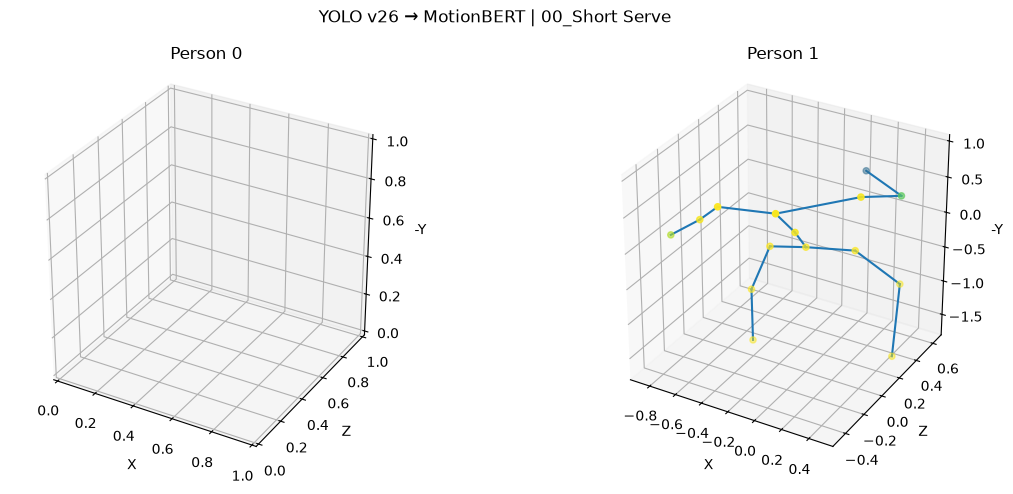

In [10]:
H36M_EDGES = [
    (0, 1), (1, 2), (2, 3),
    (0, 4), (4, 5), (5, 6),
    (0, 7), (7, 8), (8, 9), (9, 10),
    (8, 11), (11, 12), (12, 13),
    (8, 14), (14, 15), (15, 16),
]


def show_skeleton(dataset, sample_index=0, frame_index=None):
    features, label = dataset[sample_index]
    features = features.numpy()
    if frame_index is None:
        visible_frames = np.flatnonzero(features[3].sum(axis=(1, 2)) > 0)
        frame_index = int(visible_frames[len(visible_frames) // 2]) if len(visible_frames) else 0
    fig = plt.figure(figsize=(12, 5))
    for person_index in range(2):
        axis = fig.add_subplot(1, 2, person_index + 1, projection="3d")
        xyz = features[:3, frame_index, :, person_index].T
        confidence = features[3, frame_index, :, person_index]
        for start, end in H36M_EDGES:
            if confidence[start] > 0 and confidence[end] > 0:
                axis.plot(xyz[[start, end], 0], xyz[[start, end], 2],
                          -xyz[[start, end], 1], color="tab:blue")
        visible = confidence > 0
        axis.scatter(xyz[visible, 0], xyz[visible, 2], -xyz[visible, 1],
                     c=confidence[visible], cmap="viridis", vmin=0, vmax=1)
        axis.set(xlabel="X", ylabel="Z", zlabel="-Y", title=f"Person {person_index}")
        axis.set_box_aspect((1, 1, 1))
    fig.suptitle(f"YOLO v26 → MotionBERT | {class_names[int(label)]}")
    plt.tight_layout()
    plt.show()


show_skeleton(val_dataset)


### Xem ảnh keypoint qua từng frame
Mỗi ô là một frame gốc, theo thứ tự từ trái sang phải và từ trên xuống dưới. Mỗi người có lưới ảnh riêng. Giữ cùng góc nhìn và giới hạn trục cho toàn bộ clip. Không crop/padding/augmentation.
Đổi `SAMPLE_INDEX` để chọn clip; `FRAMES_PER_PAGE` để đổi số ảnh trên mỗi trang.

Clip: 2022-08-30_18-59-37_dataset_set1_008_001092_001118_A_00_joints3d.npy | 26 frame gốc
Màu điểm: confidence YOLO chuyển sang H36M (0–1).
Person 0: không có keypoint đủ confidence trong clip.


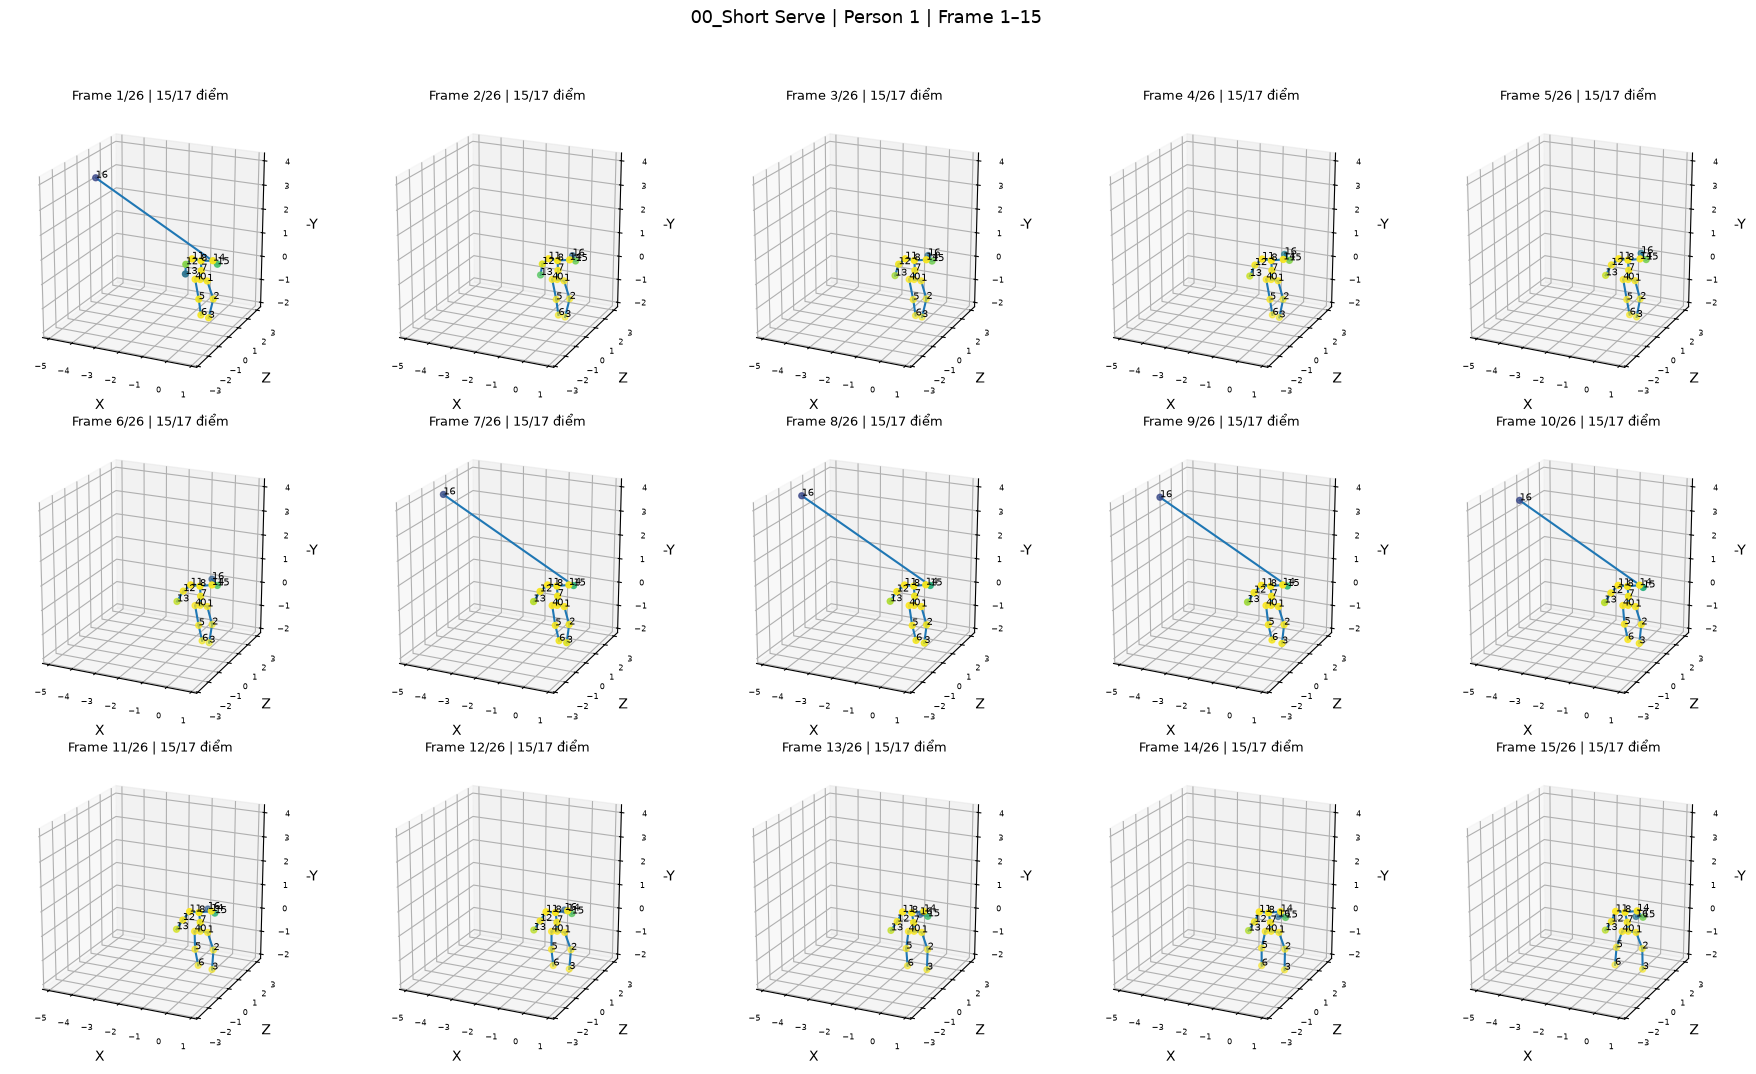

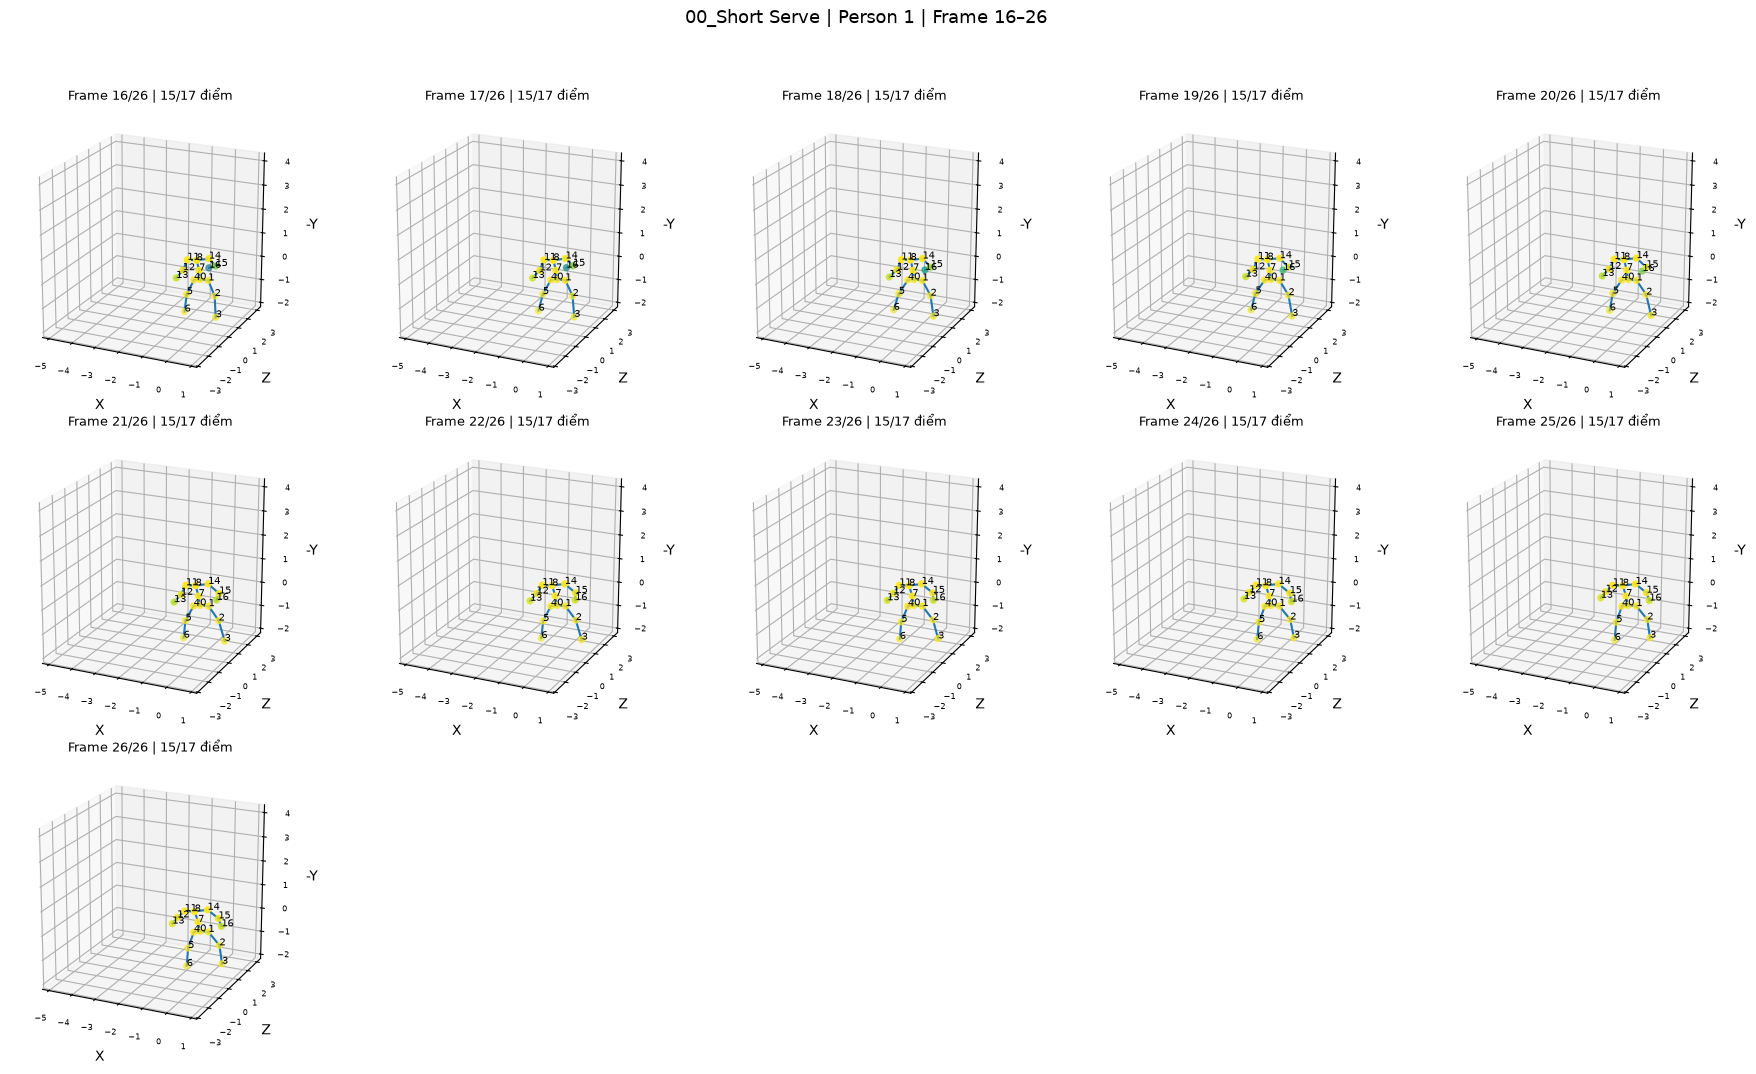

,joint_id,joint_name
0,0,Pelvis
1,1,R hip
2,2,R knee
3,3,R ankle
4,4,L hip
5,5,L knee
6,6,L ankle
7,7,Spine
8,8,Thorax
9,9,Nose


In [11]:
from IPython.display import display

H36M_JOINT_NAMES = [
    "Pelvis", "R hip", "R knee", "R ankle", "L hip", "L knee", "L ankle",
    "Spine", "Thorax", "Nose", "Head", "L shoulder", "L elbow", "L wrist",
    "R shoulder", "R elbow", "R wrist",
]


def show_pose_frames(index_df, sample_index=0, columns=5, frames_per_page=15,
                     confidence_threshold=CONFIDENCE_THRESHOLD,
                     show_joint_ids=True, normalize=True):
    """Hiển thị tất cả frame gốc thành lưới ảnh tĩnh, riêng từng người."""
    if columns < 1 or frames_per_page < 1:
        raise ValueError("columns và frames_per_page phải lớn hơn 0")
    row = index_df.iloc[sample_index]
    joints = np.load(row["joint_path"]).astype(np.float32)
    if joints.ndim != 4 or joints.shape[1:] != (2, 17, 3):
        raise ValueError(f"Shape pose không hợp lệ: {joints.shape}")
    if not len(joints) or not np.isfinite(joints).all():
        raise ValueError("Clip rỗng hoặc chứa NaN/Inf")
    scores = load_scores(row["score_path"], joints)
    if normalize:
        joints, scores = normalize_skeleton(joints, scores, confidence_threshold)
    visible = (scores > 0) & (scores >= confidence_threshold)
    xyz = joints[..., [0, 2, 1]].copy()
    xyz[..., 2] *= -1
    points = xyz[visible]
    if len(points):
        lower, upper = points.min(axis=0), points.max(axis=0)
        center = (lower + upper) / 2
        radius = max(float((upper - lower).max()) * 0.55, 0.1)
    else:
        center, radius = np.zeros(3), 1.0

    print(f"Clip: {Path(row['joint_path']).name} | {len(joints)} frame gốc")
    print("Màu điểm: confidence YOLO chuyển sang H36M (0–1).")
    for person in range(2):
        if not visible[:, person].any():
            print(f"Person {person}: không có keypoint đủ confidence trong clip.")
            continue
        for start_frame in range(0, len(joints), frames_per_page):
            end_frame = min(start_frame + frames_per_page, len(joints))
            count = end_frame - start_frame
            rows = (count + columns - 1) // columns
            fig = plt.figure(figsize=(columns * 3.6, rows * 3.6))
            for slot, frame in enumerate(range(start_frame, end_frame), start=1):
                axis = fig.add_subplot(rows, columns, slot, projection="3d")
                pose, valid = xyz[frame, person], visible[frame, person]
                for first, second in H36M_EDGES:
                    if valid[first] and valid[second]:
                        segment = pose[[first, second]]
                        axis.plot(segment[:, 0], segment[:, 1], segment[:, 2],
                                  color="tab:blue", linewidth=1.5)
                axis.scatter(pose[valid, 0], pose[valid, 1], pose[valid, 2],
                             c=scores[frame, person, valid], cmap="viridis",
                             vmin=0, vmax=1, s=18)
                if show_joint_ids:
                    for joint in np.flatnonzero(valid):
                        axis.text(*pose[joint], str(joint), fontsize=7)
                axis.set(xlabel="X", ylabel="Z", zlabel="-Y",
                         xlim=(center[0] - radius, center[0] + radius),
                         ylim=(center[1] - radius, center[1] + radius),
                         zlim=(center[2] - radius, center[2] + radius))
                axis.set_box_aspect((1, 1, 1))
                axis.view_init(elev=20, azim=-65)
                axis.tick_params(labelsize=6)
                axis.set_title(f"Frame {frame + 1}/{len(joints)} | {valid.sum()}/17 điểm",
                               fontsize=9)
            fig.suptitle(
                f"{row['label_name']} | Person {person} | "
                f"Frame {start_frame + 1}–{end_frame}", fontsize=13
            )
            fig.tight_layout(rect=(0, 0, 1, 0.95))
            plt.show()
            plt.close(fig)


SAMPLE_INDEX = 0
FRAMES_PER_PAGE = 15

show_pose_frames(val_df, sample_index=SAMPLE_INDEX,
                 columns=5, frames_per_page=FRAMES_PER_PAGE,
                 show_joint_ids=True)
display(pd.DataFrame({"joint_id": range(17), "joint_name": H36M_JOINT_NAMES}))


In [12]:
def normalize_digraph(matrix):
    degree = matrix.sum(axis=0)

    inverse_degree = np.zeros_like(
        degree,
        dtype=np.float32,
    )

    valid = degree > 0

    inverse_degree[valid] = (
        1.0 / degree[valid]
    )

    return (
        matrix
        @ np.diag(inverse_degree)
    )


def build_h36m_adjacency():
    num_joints = 17

    identity = np.eye(
        num_joints,
        dtype=np.float32,
    )

    inward = np.zeros(
        (num_joints, num_joints),
        dtype=np.float32,
    )

    for source, target in H36M_EDGES:
        inward[target, source] = 1.0

    outward = inward.T

    adjacency = np.stack(
        [
            identity,
            normalize_digraph(inward),
            normalize_digraph(outward),
        ]
    )

    return torch.tensor(
        adjacency,
        dtype=torch.float32,
    )


ADJACENCY = build_h36m_adjacency()

print("Adjacency:", ADJACENCY.shape)

Adjacency: torch.Size([3, 17, 17])


In [13]:
class SpatialGraphConv(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        spatial_kernel_size,
    ):
        super().__init__()

        self.spatial_kernel_size = (
            spatial_kernel_size
        )

        self.conv = nn.Conv2d(
            in_channels,
            out_channels
            * spatial_kernel_size,
            kernel_size=1,
        )

    def forward(
        self,
        x,
        adjacency,
    ):
        x = self.conv(x)

        n, kc, t, v = x.shape

        x = x.view(
            n,
            self.spatial_kernel_size,
            kc // self.spatial_kernel_size,
            t,
            v,
        )

        x = torch.einsum(
            "nkctv,kvw->nctw",
            x,
            adjacency,
        )

        return x.contiguous()

In [14]:
class STGCNBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        spatial_kernel_size,
        stride=1,
        dropout=0.4,
        residual=True,
    ):
        super().__init__()

        self.gcn = SpatialGraphConv(
            in_channels,
            out_channels,
            spatial_kernel_size,
        )

        self.tcn = nn.Sequential(
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=(9, 1),
                stride=(stride, 1),
                padding=(4, 0),
            ),

            nn.BatchNorm2d(out_channels),
            nn.Dropout(dropout),
        )

        if not residual:
            self.residual = lambda x: 0

        elif (
            in_channels == out_channels
            and stride == 1
        ):
            self.residual = nn.Identity()

        else:
            self.residual = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=(stride, 1),
                ),
                nn.BatchNorm2d(
                    out_channels
                ),
            )

        self.relu = nn.ReLU(
            inplace=True
        )

    def forward(
        self,
        x,
        adjacency,
    ):
        residual = self.residual(x)

        x = self.gcn(
            x,
            adjacency,
        )

        x = self.tcn(x)
        x = x + residual

        return self.relu(x)

In [15]:
class STGCNV2(nn.Module):
    def __init__(
        self,
        in_channels,
        num_classes,
        adjacency,
        dropout=0.4,
    ):
        super().__init__()

        self.register_buffer(
            "adjacency",
            adjacency,
        )

        num_joints = adjacency.shape[-1]

        self.data_bn = nn.BatchNorm1d(
            in_channels * num_joints
        )

        configurations = [
            (in_channels, 32, 1, False),
            (32, 32, 1, True),
            (32, 64, 2, True),
            (64, 64, 1, True),
            (64, 128, 2, True),
            (128, 128, 1, True),
        ]

        self.blocks = nn.ModuleList(
            [
                STGCNBlock(
                    in_channels=in_c,
                    out_channels=out_c,
                    spatial_kernel_size=(
                        adjacency.shape[0]
                    ),
                    stride=stride,
                    dropout=dropout,
                    residual=residual,
                )
                for (
                    in_c,
                    out_c,
                    stride,
                    residual,
                ) in configurations
            ]
        )

        self.edge_importance = (
            nn.ParameterList(
                [
                    nn.Parameter(
                        torch.ones_like(
                            adjacency
                        )
                    )
                    for _ in self.blocks
                ]
            )
        )

        self.person_attention = nn.Sequential(
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(
                128,
                num_classes,
            ),
        )

    def forward(
        self,
        x,
        return_attention=False,
    ):
        # x: (N, C, T, V, M)
        n, c, t, v, m = x.shape

        x = x.permute(
            0, 4, 3, 1, 2
        ).contiguous()

        x = x.view(
            n * m,
            v * c,
            t,
        )

        x = self.data_bn(x)

        x = x.view(
            n,
            m,
            v,
            c,
            t,
        )

        x = x.permute(
            0, 1, 3, 4, 2
        ).contiguous()

        x = x.view(
            n * m,
            c,
            t,
            v,
        )

        for block, importance in zip(
            self.blocks,
            self.edge_importance,
        ):
            x = block(
                x,
                self.adjacency
                * importance,
            )

        x = F.adaptive_avg_pool2d(
            x,
            output_size=1,
        )

        x = x.view(
            n,
            m,
            128,
        )

        attention_logits = (
            self.person_attention(x)
            .squeeze(-1)
        )

        attention = torch.softmax(
            attention_logits,
            dim=1,
        )

        pooled = (
            x
            * attention.unsqueeze(-1)
        ).sum(dim=1)

        logits = self.classifier(
            pooled
        )

        if return_attention:
            return logits, attention

        return logits

In [16]:
model = STGCNV2(
    in_channels=INPUT_CHANNELS,
    num_classes=len(class_names),
    adjacency=ADJACENCY,
    dropout=0.4,
).to(DEVICE)

with torch.no_grad():
    test_logits, test_attention = model(
        features_batch[:2].to(DEVICE),
        return_attention=True,
    )

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Logits:", test_logits.shape)
print("Attention:", test_attention)
print(
    "Trainable parameters:",
    f"{parameter_count:,}",
)

assert test_logits.shape == (
    2,
    len(class_names),
)

assert test_attention.shape == (
    2,
    2,
)

Logits: torch.Size([2, 18])
Attention: tensor([[0.4070, 0.5930],
        [0.4965, 0.5035]], device='cuda:0')
Trainable parameters: 513,459


In [17]:
train_counts = (
    train_df["label_name"]
    .value_counts()
    .reindex(class_names)
    .to_numpy()
)

class_weights = (
    len(train_df)
    / (
        len(class_names)
        * train_counts
    )
)

# Không để lớp hiếm có trọng số quá lớn.
class_weights = np.clip(
    class_weights,
    0.5,
    3.0,
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

print("Class weights:")

display(
    pd.DataFrame(
        {
            "class": class_names,
            "train_count": train_counts,
            "weight": (
                class_weights.cpu().numpy()
            ),
        }
    )
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

warmup_scheduler = (
    torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=0.2,
        end_factor=1.0,
        total_iters=WARMUP_EPOCHS,
    )
)

cosine_scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingLR(
        optimizer,
        T_max=(
            NUM_EPOCHS
            - WARMUP_EPOCHS
        ),
        eta_min=1e-6,
    )
)

scheduler = (
    torch.optim.lr_scheduler
    .SequentialLR(
        optimizer,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler,
        ],
        milestones=[
            WARMUP_EPOCHS,
        ],
    )
)

Class weights:


,class,train_count,weight
0,00_Short Serve,619,0.500000
1,01_Cross Court Flight,111,2.733734
2,02_Lift,529,0.573619
3,03_Tap Smash,73,3.000000
4,04_Block,214,1.417965
5,05_Drop Shot,560,0.541865
6,06_Push Shot,300,1.011482
7,07_Transitional Slice,79,3.000000
8,08_Cut,406,0.747400
9,09_Rush Shot,102,2.974946


In [18]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
):
    training = optimizer is not None

    model.train(training)

    total_loss = 0.0
    y_true = []
    y_pred = []

    progress = tqdm(
        loader,
        leave=False,
        desc=(
            "Train"
            if training
            else "Validation"
        ),
    )

    for features, labels in progress:
        features = features.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            training
        ):
            logits = model(features)

            loss = criterion(
                logits,
                labels,
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=5.0,
                )

                optimizer.step()

        total_loss += (
            loss.item()
            * len(labels)
        )

        predictions = logits.argmax(
            dim=1
        )

        y_true.extend(
            labels
            .detach()
            .cpu()
            .tolist()
        )

        y_pred.extend(
            predictions
            .detach()
            .cpu()
            .tolist()
        )

    return {
        "loss": (
            total_loss
            / len(loader.dataset)
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }

In [19]:
CHECKPOINT_PATH = (
    OUTPUT_ROOT
    / "stgcn_v2_motionbert_best.pt"
)

history = []

best_val_f1 = -1.0
best_epoch = 0

for epoch in range(
    1,
    NUM_EPOCHS + 1,
):
    started = time.time()

    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
    )

    val_metrics = run_epoch(
        model,
        val_loader,
        criterion,
    )

    scheduler.step()

    result = {
        "epoch": epoch,
        "train_loss": (
            train_metrics["loss"]
        ),
        "train_accuracy": (
            train_metrics["accuracy"]
        ),
        "train_macro_f1": (
            train_metrics["macro_f1"]
        ),
        "val_loss": (
            val_metrics["loss"]
        ),
        "val_accuracy": (
            val_metrics["accuracy"]
        ),
        "val_macro_f1": (
            val_metrics["macro_f1"]
        ),
        "learning_rate": (
            optimizer.param_groups[0]["lr"]
        ),
        "seconds": (
            time.time() - started
        ),
    }

    history.append(result)

    print(
        f"Epoch {epoch:03d} | "
        f"train loss={result['train_loss']:.4f}, "
        f"f1={result['train_macro_f1']:.4f}, "
        f"acc={result['train_accuracy']:.4f} | "
        f"val loss={result['val_loss']:.4f}, "
        f"f1={result['val_macro_f1']:.4f}, "
        f"acc={result['val_accuracy']:.4f} | "
        f"lr={result['learning_rate']:.2e} | "
        f"{result['seconds']:.1f}s"
    )

    if (
        result["val_macro_f1"]
        > best_val_f1
    ):
        best_val_f1 = (
            result["val_macro_f1"]
        )

        best_epoch = epoch

        torch.save(
            {
                "model_state": (
                    model.state_dict()
                ),
                "class_names": class_names,
                "target_frames": (
                    TARGET_FRAMES
                ),
                "input_channels": INPUT_CHANNELS,
                "input_features": INPUT_FEATURES,
                "joint_layout": "Human3.6M",
                "pose_pipeline": "YOLO v26 → MotionBERT",
                "best_epoch": best_epoch,
                "best_val_macro_f1": (
                    best_val_f1
                ),
            },
            CHECKPOINT_PATH,
        )

        print(
            "  Đã lưu checkpoint tốt nhất"
        )



history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_ROOT
    / "training_history.csv",
    index=False,
)

print("Best epoch:", best_epoch)
print(
    "Best validation Macro F1:",
    best_val_f1,
)

Epoch 001 | train loss=2.9813, f1=0.0686, acc=0.0835 | val loss=3.0239, f1=0.0332, acc=0.0808 | lr=3.60e-04 | 4.9s
  Đã lưu checkpoint tốt nhất


Epoch 002 | train loss=2.8248, f1=0.1243, acc=0.1873 | val loss=3.0699, f1=0.0914, acc=0.2985 | lr=5.20e-04 | 3.2s
  Đã lưu checkpoint tốt nhất


Epoch 003 | train loss=2.6103, f1=0.2065, acc=0.3202 | val loss=2.6949, f1=0.1944, acc=0.3835 | lr=6.80e-04 | 3.2s
  Đã lưu checkpoint tốt nhất


Epoch 004 | train loss=2.4800, f1=0.2461, acc=0.3828 | val loss=3.9598, f1=0.1210, acc=0.1939 | lr=8.40e-04 | 3.2s


Epoch 005 | train loss=2.3724, f1=0.2731, acc=0.4114 | val loss=4.3010, f1=0.0939, acc=0.1624 | lr=1.00e-03 | 3.2s


Epoch 006 | train loss=2.3091, f1=0.2942, acc=0.4301 | val loss=4.8912, f1=0.1003, acc=0.2628 | lr=1.00e-03 | 3.2s


... (90 outputs left out)

Epoch 097 | train loss=1.2979, f1=0.6664, acc=0.7208 | val loss=2.1916, f1=0.4007, acc=0.5867 | lr=3.46e-06 | 3.2s


Epoch 098 | train loss=1.2949, f1=0.6763, acc=0.7276 | val loss=2.1597, f1=0.4047, acc=0.5935 | lr=2.09e-06 | 3.2s


Epoch 099 | train loss=1.3044, f1=0.6694, acc=0.7201 | val loss=2.1566, f1=0.4095, acc=0.6029 | lr=1.27e-06 | 3.2s


Epoch 100 | train loss=1.3180, f1=0.6642, acc=0.7201 | val loss=2.2379, f1=0.3883, acc=0.5723 | lr=1.00e-06 | 3.2s
Best epoch: 23
Best validation Macro F1: 0.41603268196739623


In [20]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["model_state"]
)

print(
    "Đã nạp best epoch:",
    checkpoint["best_epoch"],
)

print(
    "Best validation Macro F1:",
    checkpoint["best_val_macro_f1"],
)

Đã nạp best epoch: 23
Best validation Macro F1: 0.41603268196739623


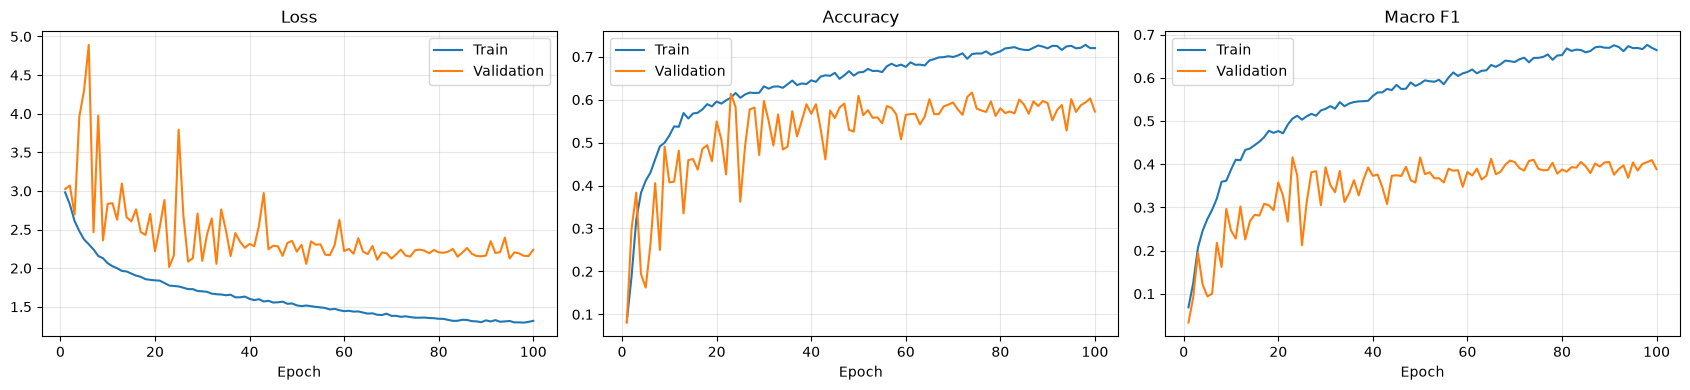

In [21]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 4),
)

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train",
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation",
)

axes[0].set_title("Loss")

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train",
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation",
)

axes[1].set_title("Accuracy")

axes[2].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train",
)

axes[2].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation",
)

axes[2].set_title("Macro F1")

for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "training_curves.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [22]:
@torch.no_grad()
def predict_dataset(
    model,
    loader,
):
    model.eval()

    y_true = []
    y_pred = []
    probabilities = []
    attention_values = []

    for features, labels in tqdm(
        loader,
        desc="Test",
    ):
        features = features.to(
            DEVICE,
            non_blocking=True,
        )

        logits, attention = model(
            features,
            return_attention=True,
        )

        probability = (
            logits
            .softmax(dim=1)
            .cpu()
        )

        y_true.extend(
            labels.tolist()
        )

        y_pred.extend(
            probability
            .argmax(dim=1)
            .tolist()
        )

        probabilities.append(
            probability
        )

        attention_values.append(
            attention.cpu()
        )

    return (
        np.asarray(y_true),
        np.asarray(y_pred),
        torch.cat(
            probabilities
        ).numpy(),
        torch.cat(
            attention_values
        ).numpy(),
    )


(
    y_true,
    y_pred,
    y_probability,
    person_attention,
) = predict_dataset(
    model,
    test_loader,
)

test_accuracy = accuracy_score(
    y_true,
    y_pred,
)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

print(
    f"Test accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Macro F1: "
    f"{test_macro_f1:.4f}"
)

Test: 100%|██████████| 19/19 [00:00<00:00, 37.35it/s]

Test accuracy: 0.6390
Test Macro F1: 0.4209


In [23]:
report_text = classification_report(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    target_names=class_names,
    zero_division=0,
)

print(report_text)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

with open(
    OUTPUT_ROOT
    / "classification_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        report_dict,
        file,
        indent=2,
        ensure_ascii=False,
    )

                          precision    recall  f1-score   support

          00_Short Serve       0.73      1.00      0.84       132
   01_Cross Court Flight       0.40      0.06      0.10        35
                 02_Lift       0.56      0.57      0.56       127
            03_Tap Smash       0.00      0.00      0.00        21
                04_Block       0.44      0.66      0.53        59
            05_Drop Shot       0.59      0.60      0.60       122
            06_Push Shot       0.29      0.45      0.36        51
   07_Transitional Slice       0.50      0.11      0.18        18
                  08_Cut       0.58      0.62      0.60       101
            09_Rush Shot       0.00      0.00      0.00         6
      10_Defensive Clear       0.14      0.22      0.17         9
      11_Defensive Drive       0.00      0.00      0.00         0
                12_Clear       0.82      0.68      0.74       143
           13_Long Serve       0.79      0.87      0.83       150
         

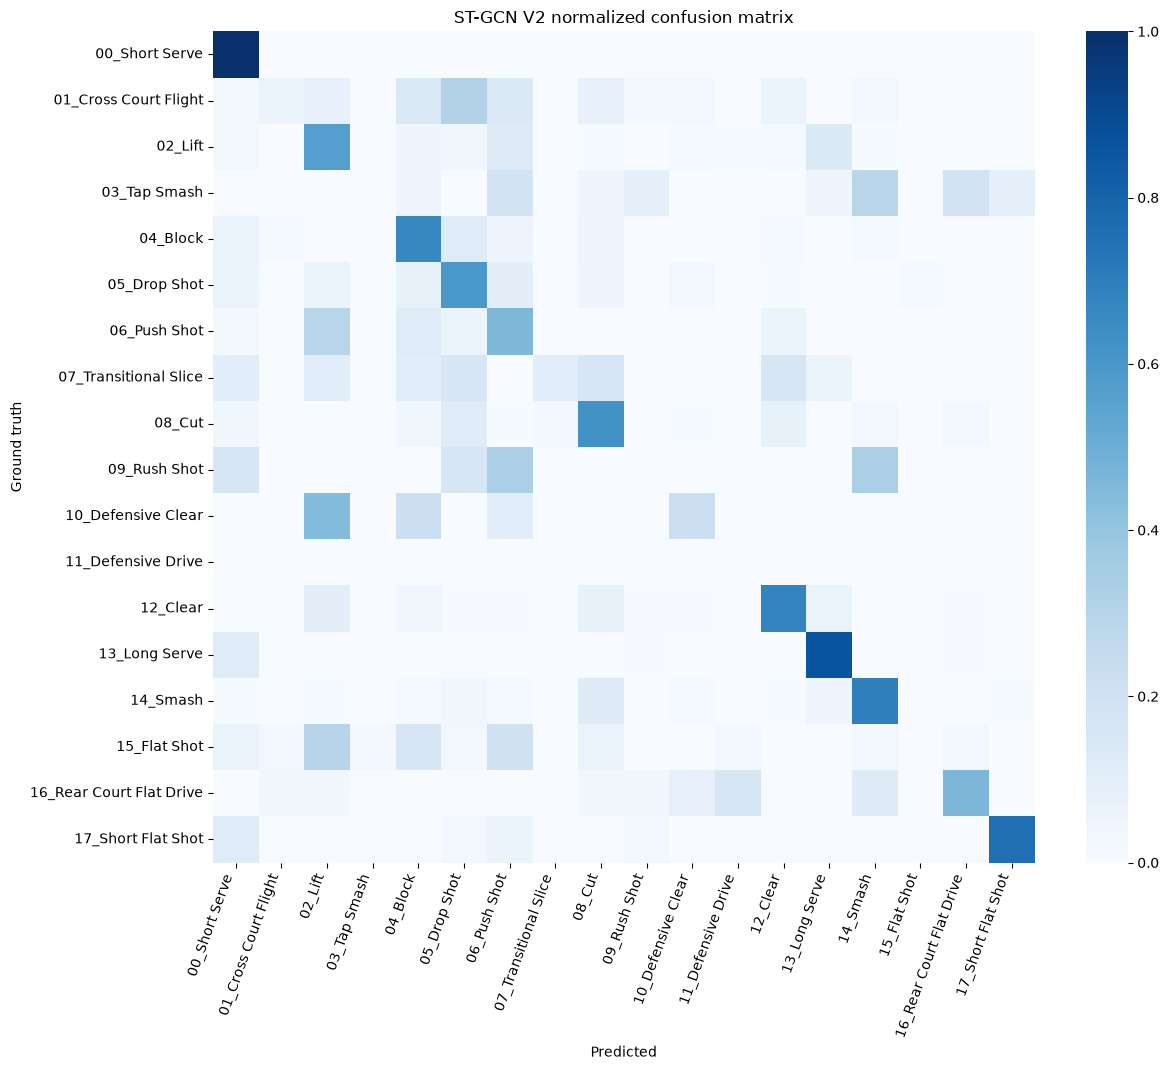

In [24]:
matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
    normalize="true",
)

plt.figure(
    figsize=(
        max(
            11,
            len(class_names) * 0.7,
        ),
        max(
            9,
            len(class_names) * 0.6,
        ),
    )
)

sns.heatmap(
    matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1,
)

plt.xlabel("Predicted")
plt.ylabel("Ground truth")
plt.title(
    "ST-GCN V2 normalized confusion matrix"
)

plt.xticks(
    rotation=70,
    ha="right",
)

plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [25]:
prediction_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

prediction_df["true_label"] = [
    class_names[index]
    for index in y_true
]

prediction_df["predicted_label"] = [
    class_names[index]
    for index in y_pred
]

prediction_df["confidence"] = (
    y_probability.max(axis=1)
)

prediction_df["correct"] = (
    y_true == y_pred
)

prediction_df["person_0_attention"] = (
    person_attention[:, 0]
)

prediction_df["person_1_attention"] = (
    person_attention[:, 1]
)

prediction_df.to_csv(
    OUTPUT_ROOT
    / "test_predictions.csv",
    index=False,
)

print("Dự đoán sai có confidence cao:")

display(
    prediction_df[
        ~prediction_df["correct"]
    ]
    .sort_values(
        "confidence",
        ascending=False,
    )
    .head(20)
)

Dự đoán sai có confidence cao:


,split,label_name,joint_path,score_path,true_label,predicted_label,confidence,correct,person_0_attention,person_1_attention
381,test,05_Drop Shot,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,05_Drop Shot,00_Short Serve,0.976485,False,0.460282,0.539718
963,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.975465,False,0.380642,0.619358
957,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.973610,False,0.441820,0.558180
969,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.972376,False,0.367439,0.632561
958,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.970673,False,0.442182,0.557818
961,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.969727,False,0.393387,0.606613
956,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.967713,False,0.442953,0.557047
959,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.965991,False,0.371457,0.628543
877,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,09_Rush Shot,0.956455,False,0.651235,0.348765
964,test,13_Long Serve,/home/dutai/khacbinh/badminton-stroke/processe...,/home/dutai/khacbinh/badminton-stroke/processe...,13_Long Serve,00_Short Serve,0.952283,False,0.378058,0.621942


,class_id,class_name,correct,total,accuracy
3,3,03_Tap Smash,0,21,0.000000
15,15,15_Flat Shot,0,30,0.000000
11,11,11_Defensive Drive,0,0,0.000000
9,9,09_Rush Shot,0,6,0.000000
1,1,01_Cross Court Flight,2,35,0.057143
7,7,07_Transitional Slice,2,18,0.111111
10,10,10_Defensive Clear,2,9,0.222222
6,6,06_Push Shot,23,51,0.450980
16,16,16_Rear Court Flat Drive,11,24,0.458333
2,2,02_Lift,72,127,0.566929


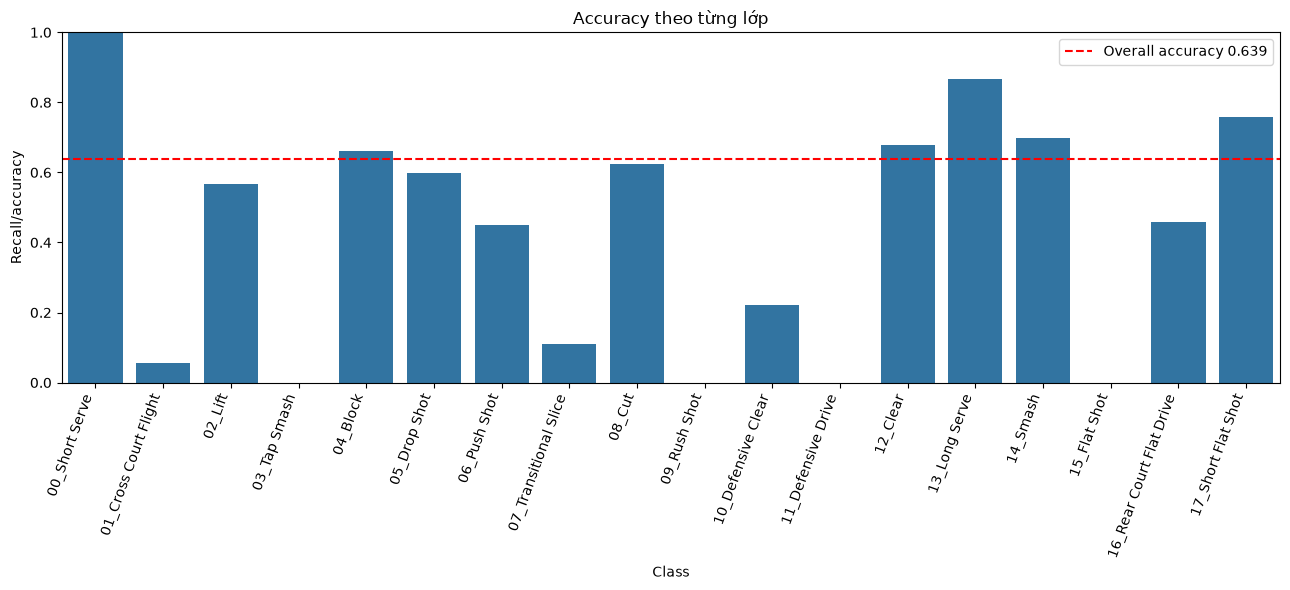

In [26]:
per_class_records = []

for class_id, class_name in enumerate(
    class_names
):
    indices = y_true == class_id
    total = int(indices.sum())

    correct = int(
        (
            y_pred[indices]
            == class_id
        ).sum()
    )

    accuracy = (
        correct / total
        if total > 0
        else 0.0
    )

    per_class_records.append(
        {
            "class_id": class_id,
            "class_name": class_name,
            "correct": correct,
            "total": total,
            "accuracy": accuracy,
        }
    )

per_class_df = pd.DataFrame(
    per_class_records
)

display(
    per_class_df.sort_values(
        "accuracy"
    )
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=per_class_df,
    x="class_name",
    y="accuracy",
)

plt.axhline(
    test_accuracy,
    color="red",
    linestyle="--",
    label=(
        f"Overall accuracy "
        f"{test_accuracy:.3f}"
    ),
)

plt.xticks(
    rotation=70,
    ha="right",
)

plt.ylim(0, 1)
plt.xlabel("Class")
plt.ylabel("Recall/accuracy")
plt.title("Accuracy theo từng lớp")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
confusion_counts = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(class_names)
    ),
)

confusion_records = []

for true_id in range(
    len(class_names)
):
    for predicted_id in range(
        len(class_names)
    ):
        if true_id == predicted_id:
            continue

        count = int(
            confusion_counts[
                true_id,
                predicted_id,
            ]
        )

        if count > 0:
            confusion_records.append(
                {
                    "true_label": (
                        class_names[true_id]
                    ),
                    "predicted_label": (
                        class_names[predicted_id]
                    ),
                    "count": count,
                }
            )

confusion_pairs_df = pd.DataFrame(
    confusion_records,
    columns=["true_label", "predicted_label", "count"],
).sort_values(
    "count",
    ascending=False,
)

display(
    confusion_pairs_df.head(30)
)

,true_label,predicted_label,count
80,13_Long Serve,00_Short Serve,18
18,02_Lift,13_Long Serve,17
13,02_Lift,06_Push Shot,16
71,12_Clear,02_Lift,15
88,14_Smash,08_Cut,15
44,06_Push Shot,02_Lift,15
38,05_Drop Shot,06_Push Shot,12
57,08_Cut,05_Drop Shot,12
3,01_Cross Court Flight,05_Drop Shot,11
75,12_Clear,08_Cut,11


In [28]:
metadata = {
    "model": "ST-GCN V2",
    "pose_pipeline": "YOLO v26 → MotionBERT → ST-GCN",
    "joint_layout": "Human3.6M",
    "joints_root": str(JOINTS_ROOT),
    "scores_root": str(SCORES_ROOT),
    "confidence_source": "YOLO 2D converted to H36M",
    "input_channels": INPUT_FEATURES,
    "target_frames": TARGET_FRAMES,
    "num_joints": 17,
    "num_persons": 2,
    "num_classes": len(class_names),
    "class_names": class_names,
    "best_epoch": int(
        checkpoint["best_epoch"]
    ),
    "best_val_macro_f1": float(
        checkpoint[
            "best_val_macro_f1"
        ]
    ),
    "test_accuracy": float(
        test_accuracy
    ),
    "test_macro_f1": float(
        test_macro_f1
    ),
    "seed": SEED,
}

with open(
    OUTPUT_ROOT
    / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )

print(
    "Đã lưu kết quả tại:",
    OUTPUT_ROOT,
)

Đã lưu kết quả tại: /home/dutai/khacbinh/badminton-stroke/processed/stgcn_v2_yolo26_motionbert
